#Pre Entrega 4 -Grupo 11- Comision 3: Aprendizaje No Supervisado

Integrantes: Facenda Selena, Ferreyra Iara y Biaiñ Joaquin

  ## 1. Carga de Datos e Ingeniería de Características Petrofísicas
En esta primera etapa del flujo no supervisado, realizamos la carga del dataset de facies.

Para garantizar la robustez analítica, se realizó el filtrado de valores nulos y se estructuraron nuevas variables.

Finalmente, las variables numéricas se escalaron utilizando `StandardScaler` para asegurar el correcto funcionamiento de algoritmos basados en distancias como K-Means.

In [8]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# 1. Carga del dataset
if os.path.exists("/content/facies_data.csv"):
    df = pd.read_csv("/content/facies_data.csv")
elif os.path.exists("facies_data.csv"):
    df = pd.read_csv("facies_data.csv")
else:
    url_seg = "https://raw.githubusercontent.com/seg/2016-ml-contest/master/facies_vectors.csv"
    df = pd.read_csv(url_seg)

df = df.dropna().sort_values(['Well Name', 'Depth']).reset_index(drop=True)

# 2. Definición de Variables Petrofísicas y Estratigráficas
def agregar_features_petrofisicas(data):
    d = data.copy()
    log_cols = ['GR', 'ILD_log10', 'DeltaPHI', 'PHIND', 'PE']
    g_well = d.groupby('Well Name')
    g_well_nm = d.groupby(['Well Name', 'NM_M'])
    well_sizes = g_well['GR'].transform('count')
    nm_means = d.groupby('NM_M')[log_cols].transform('mean')
    nm_stds = d.groupby('NM_M')[log_cols].transform('std')

    for col in log_cols:
        w_z = g_well[col].transform(lambda x: (x - x.mean()) / (x.std() + 1e-6))
        nm_z = g_well_nm[col].transform(lambda x: (x - x.mean()) / (x.std() + 1e-6))
        glob_nm_z = (d[col] - nm_means[col]) / (nm_stds[col] + 1e-6)

        d[f'{col}_well_z'] = np.where(well_sizes > 100, w_z, glob_nm_z)
        d[f'{col}_nm_z'] = np.where(well_sizes > 100, nm_z, glob_nm_z)
        d[f'{col}_roll5_mean'] = g_well[col].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        d[f'{col}_roll5_z'] = g_well[f'{col}_well_z'].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        d[f'{col}_diff1'] = g_well[col].diff(1).fillna(0)
        d[f'{col}_lag1'] = g_well[col].shift(1).bfill()
        d[f'{col}_lead1'] = g_well[col].shift(-1).ffill()
    return d

df_feat = agregar_features_petrofisicas(df)

# 3. Seleccion de features numéricas para el modelo no supervisado
numeric_features = [c for c in df_feat.columns if c not in ['Facies', 'Formation', 'Well Name', 'Depth', 'NM_M']]
X_cluster = df_feat[numeric_features]
y_true = df_feat['Facies']

# 4. Escalado de datos (Crucial para K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print(f"Dimensiones de la matriz escalada para clustering: {X_scaled.shape}")

Dimensiones de la matriz escalada para clustering: (3232, 41)



 ## 2. Análisis de Componentes Principales (PCA)
Para analizar la estructura de la varianza en el espacio de 41 características petrofísicas, implementamos un **Análisis de Componentes Principales (PCA)** completo.

Mediante la curva de varianza acumulada, evaluamos cuántas dimensiones se requieren para capturar umbrales de información representativos (como el 80% y el 90%).

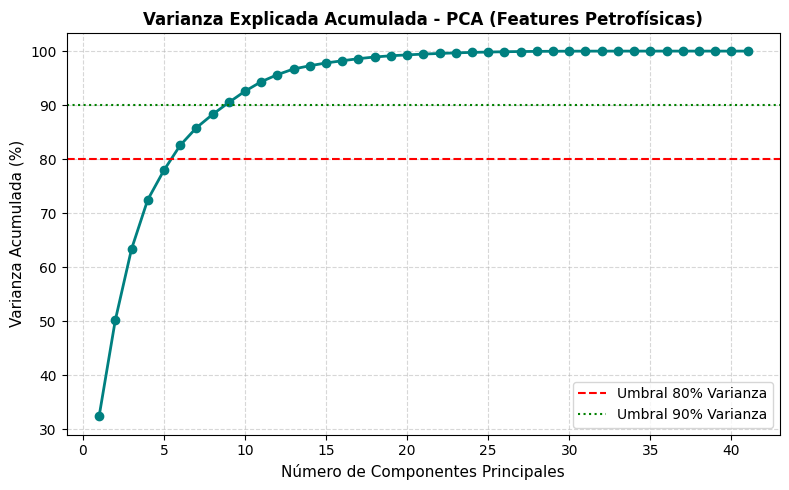

In [2]:
# Aplicación PCA para analizar la varianza
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

var_exp = pca_full.explained_variance_ratio_ * 100
cumsum_var = np.cumsum(var_exp)

# Gráfico de Varianza Explicada (con umbrales del 80% y 90% en porcentaje)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumsum_var) + 1), cumsum_var, marker='o', linestyle='-', color='teal', linewidth=2)
plt.axhline(y=80, color='r', linestyle='--', label='Umbral 80% Varianza')
plt.axhline(y=90, color='g', linestyle=':', label='Umbral 90% Varianza')
plt.title('Varianza Explicada Acumulada - PCA (Features Petrofísicas)', fontsize=12, fontweight='bold')
plt.xlabel('Número de Componentes Principales', fontsize=11)
plt.ylabel('Varianza Acumulada (%)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

##Análisis del Gráfico de PCA:

El grafico muestra la proporción de varianza total retenida en el espacio al proyectar las 41 características petrofísicas originales sobre un conjunto reducido de Componentes Principales ortogonales.

Ademas, la curva muestra un comportamiento asintótico típico. El 80% de la varianza se alcanza rápidamente (alrededor de la componente 5 o 6), mientras que el umbral del 90% se cruza cerca de la componente 9.

Esto demuestra que las primeras 10 variables petrofísicas y sus derivadas (como registros de rayos gamma, densidades y porosidades con sus desvíos y rezagos) contienen una alta redundancia y correlación física.

Mientras que las demas, tienen un porcentaje de varianza mucho menor.
Esto valida la compresión de dimensionalidad sin perder la variabilidad geológica esencial del reservorio.

##3. Optimización de K: Método del Codo y Coeficiente de Silueta.

Para determinar el número óptimo de agrupamientos ($K$), se evaluó un rango de $K$ entre 2 y 12 sobre los **primeros 10 componentes principales (`X_pca_10`)** —que retienen el **92.57%** de la varianza total—, analizando la inercia (método del codo) y el coeficiente de silueta calculado sobre la totalidad de las muestras.


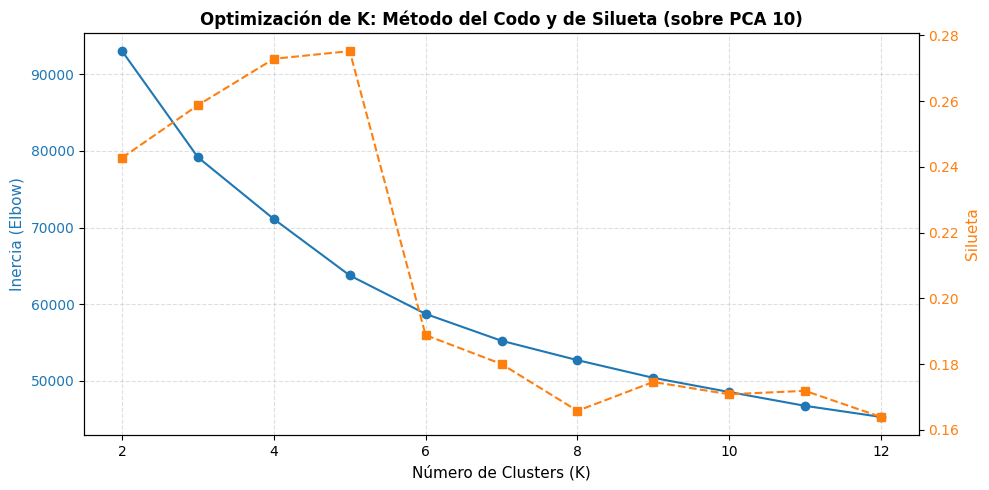

In [9]:
# Extracción de los primeros 10 componentes principales (retienen 92.57% de la varianza)
X_pca_10 = pca_full.transform(X_scaled)[:, :10]

inertias = []
silhouette_scores = []
K_range = range(2, 13)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(X_pca_10)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_pca_10, labels))

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Número de Clusters (K)', fontsize=11)
ax1.set_ylabel('Inercia (Elbow)', color=color, fontsize=11)
ax1.plot(K_range, inertias, marker='o', color=color, label='Inercia')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Silueta', color=color, fontsize=11)
ax2.plot(K_range, silhouette_scores, marker='s', color=color, linestyle='--', label='Silueta')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Optimización de K: Método del Codo y de Silueta (sobre PCA 10)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretación del Gráfico de Optimización de $K$ (sobre PCA 10)

En el grafico se observa la dualidad entre la **Inercia** (suma de distancias cuadráticas intra-clúster, que siempre decrece al aumentar $K$) y el **Coeficiente de Silueta** (que evalúa simultáneamente la cohesión interna y la separación respecto al clúster vecino más cercano).

A partir de esto, se interpreto que, mientras la inercia presenta una caída suavizada sin un quiebre abrupto (comportamiento habitual en registros geofísicos continuos), el coeficiente de silueta crece de forma sostenida hasta alcanzar su **máximo global en $K=5$ (`0.2752`)**, desplomándose abruptamente a `0.1888` en $K=6$[cite: 21].

Entonces, desde una perspectiva estrictamente no supervisada, agrupar los datos en 5 electrofacies maximiza la cohesión interna y la separación geométrica de los grupos sobre el espacio reducido, sin sobrefragmentar las litologías en subparticiones redundantes.

##4. Entrenamiento del Modelo K-Means con $K = 5$
Configuramos y entrenamos el modelo K-Means fijando el valor en $K = 5$.

Este número de agrupamientos representa las facies principales y físicamente distinguibles a partir de las respuestas de los registros de pozo.

In [10]:
# Entrenamiento K-Means con K = 5 (Óptimo estadístico no supervisado)
optimal_k = 5
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_labels = kmeans_final.fit_predict(X_pca_10)

# Se añadio etiquetas al DataFrame
df_feat['Cluster'] = cluster_labels

# Cálculo de métricas de validación externa como referencia comparativa
ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"Resultados del Modelo K-Means (K = {optimal_k}):")
print(f"  - Adjusted Rand Index (ARI):           {ari:.4f}")
print(f"  - Normalized Mutual Information (NMI): {nmi:.4f}")

Resultados del Modelo K-Means (K = 5):
  - Adjusted Rand Index (ARI):           0.1916
  - Normalized Mutual Information (NMI): 0.2817


Para evaluar cuantitativamente el desempeño del modelo no supervisado frente a las etiquetas geológicas reales de referencia, se utilizaron dos métricas de validación externa: el **Índice Rand Ajustado (ARI)** y la **Información Mutua Normalizada (NMI)**.

- **Adjusted Rand Index (`ARI = 0.1916`):**
  
  Cuantifica la similitud entre las parejas de muestras agrupadas en los clústeres y las agrupaciones reales, corrigiendo el efecto del azar.

   Un valor de `0.1916` refleja una concordancia baja a moderada. Esto es completamente esperable en un enfoque no supervisado aplicado a datos petrofísicos de pozos: `K-Means` agrupa puramente por proximidad geométrica en el espacio reducido de **10 componentes principales (`X_pca_10`)**, sin conocer las reglas sedimentológicas estrictas.
   
   Las 9 litofacies originales del dataset presentan solapamientos físicos considerables en sus respuestas de registros, lo que impide una separación lineal perfecta mediante distancias euclidianas simples.

- **Normalized Mutual Information (`NMI = 0.2817`):**
  
  
  Es una métrica que evalúa cuánta incertidumbre sobre las facies reales se reduce al conocer los clústeres asignados, normalizada entre `0` (independencia total) y `1` (correlación perfecta).

  
  El valor de `0.2817` indica una dependencia mutua no trivial y estadísticamente significativa entre las electrofacies halladas por el modelo y las litofacies geológicas. Confirma que, a pesar de las limitaciones de un algoritmo no supervisado, el espacio reducido de componentes principales retiene una señal litológica subyacente relevante que justifica la definición de las 5 electrofacies principales.

##5. Análisis de Resultados mediante Matriz de Contingencia ($K = 5$)
Generamos la matriz de contingencia normalizada por filas para examinar cómo se distribuyen las 9 litofacies geológicas reales entre los 5 clústeres no supervisados resultantes.

Esto permite entender qué familias litológicas agrupa el modelo de forma natural debido a sus similitudes en las respuestas físicas de los registros.

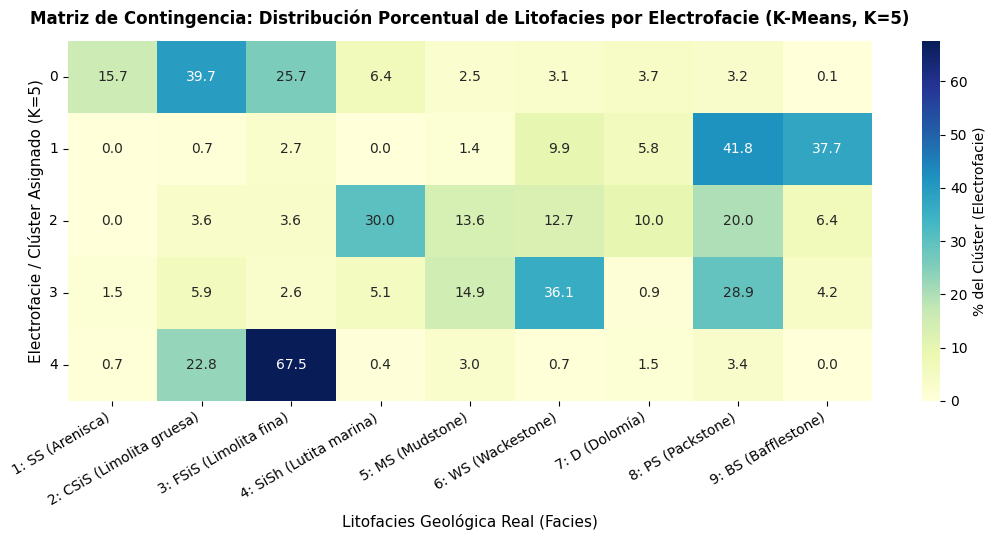

In [12]:
facies_nombres = {
    1: '1: SS (Arenisca)', 2: '2: CSiS (Limolita gruesa)', 3: '3: FSiS (Limolita fina)',
    4: '4: SiSh (Lutita marina)', 5: '5: MS (Mudstone)', 6: '6: WS (Wackestone)',
    7: '7: D (Dolomía)', 8: '8: PS (Packstone)', 9: '9: BS (Bafflestone)'
}

# Cada fila es un clúster (0 a 4) y suma 100% horizontalmente
contingency_matrix = pd.crosstab(
    df_feat['Cluster'],
    df_feat['Facies'].map(facies_nombres),
    normalize='index'
) * 100

plt.figure(figsize=(11, 5.5))
sns.heatmap(
    contingency_matrix, annot=True, fmt='.1f', cmap='YlGnBu',
    cbar_kws={'label': '% del Clúster (Electrofacie)'}
)



plt.title(
    'Matriz de Contingencia: Distribución Porcentual de Litofacies por Electrofacie (K-Means, K=5)',
    fontsize=12, fontweight='bold', pad=12
)
plt.xlabel('Litofacies Geológica Real (Facies)', fontsize=11)
plt.ylabel('Electrofacie / Clúster Asignado (K=5)', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Correlación Estratigráfica: Litofacies vs. Electrofacies — Pozo
En esta sección se presenta el perfil de correlación vertical para el pozo **{pozo_seleccionado}**, contrastando la secuencia litológica real de referencia frente a la zonificación obtenida por el modelo no supervisado de K-Means ($K=5$).

Este control visual a lo largo de la profundidad (depth) permite evaluar el desempeño geológico de las electrofacies:

* **Resolución de horizontes clave:** Permite identificar qué unidades litológicas (como tramos arenosos o arcillosos limpios) logran ser discriminadas de manera automática por el espacio reducido de componentes principales.
* **Análisis de transiciones:** Ayuda a visualizar las limitaciones físicas de un enfoque no supervisado en zonas de transición lito-estratigráfica gradual, donde las respuestas de los registros (como el Rayos Gamma o la Densidad) presentan solapamientos.

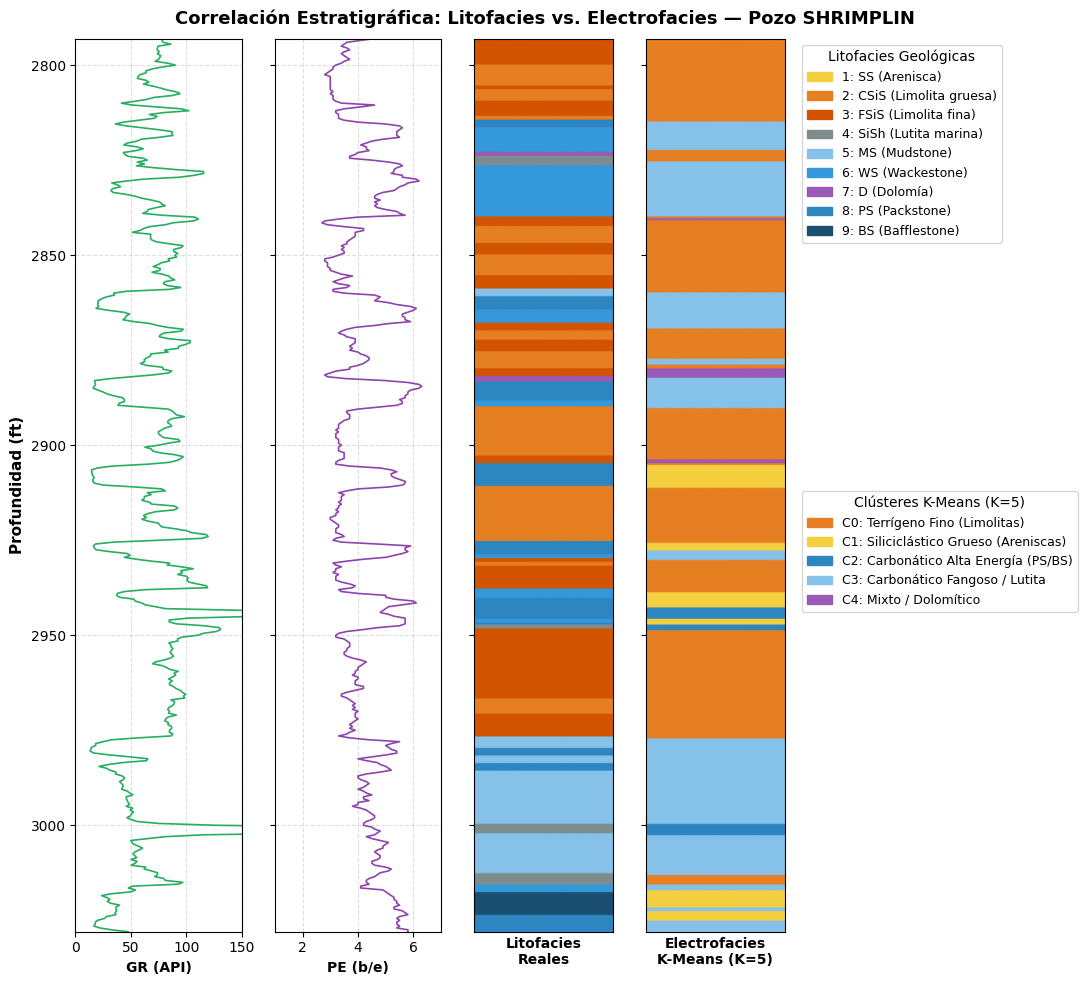

In [13]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np

# Asegurar que la columna 'Cluster' exista prediciendo con el modelo entrenado si no está presente
if 'Cluster' not in df_feat.columns:
    df_feat['Cluster'] = kmeans_final.predict(X_pca_10)

# 1. Seleccionamos el pozo directamente desde df_feat (que ya tiene la columna 'Cluster')
pozo_seleccionado = 'SHRIMPLIN'
df_pozo = df_feat[df_feat['Well Name'] == pozo_seleccionado].sort_values(
    'Depth'
)

# 2. Configuración de paletas de colores y etiquetas
facies_colors = [
    '#F4D03F',
    '#E67E22',
    '#D35400',
    '#7F8C8D',
    '#85C1E9',
    '#3498DB',
    '#9B59B6',
    '#2E86C1',
    '#1B4F72',
]
facies_labels = [
    '1: SS (Arenisca)',
    '2: CSiS (Limolita gruesa)',
    '3: FSiS (Limolita fina)',
    '4: SiSh (Lutita marina)',
    '5: MS (Mudstone)',
    '6: WS (Wackestone)',
    '7: D (Dolomía)',
    '8: PS (Packstone)',
    '9: BS (Bafflestone)',
]

cluster_colors = ['#E67E22', '#F4D03F', '#2E86C1', '#85C1E9', '#9B59B6']
cluster_labels = [
    'C0: Terrígeno Fino (Limolitas)',
    'C1: Siliciclástico Grueso (Areniscas)',
    'C2: Carbonático Alta Energía (PS/BS)',
    'C3: Carbonático Fangoso / Lutita',
    'C4: Mixto / Dolomítico',
]

cmap_facies = mcolors.ListedColormap(facies_colors)
cmap_clusters = mcolors.ListedColormap(cluster_colors)

# 3. Construcción del gráfico de perfiles verticales
fig, axes = plt.subplots(
    nrows=1,
    ncols=4,
    figsize=(11, 10),
    sharey=True,
    gridspec_kw={'width_ratios': [1.2, 1.2, 1, 1]},
)

depth = df_pozo['Depth'].values

# Pista 1: Rayos Gamma (GR)
axes[0].plot(df_pozo['GR'], depth, color='#27AE60', lw=1.2)
axes[0].set_xlabel('GR (API)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Profundidad (ft)', fontsize=11, fontweight='bold')
axes[0].set_xlim(0, 150)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].invert_yaxis()

# Pista 2: Efecto Fotoeléctrico (PE)
axes[1].plot(df_pozo['PE'], depth, color='#8E44AD', lw=1.2)
axes[1].set_xlabel('PE (b/e)', fontsize=10, fontweight='bold')
axes[1].set_xlim(1, 7)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Pista 3: Litofacies Reales (1 a 9)
facies_array = df_pozo['Facies'].values.reshape(-1, 1)
axes[2].imshow(
    facies_array,
    aspect='auto',
    cmap=cmap_facies,
    vmin=1,
    vmax=9,
    extent=[0, 1, depth.max(), depth.min()],
)
axes[2].set_xlabel('Litofacies\nReales', fontsize=10, fontweight='bold')
axes[2].set_xticks([])

# Pista 4: Electrofacies K-Means (K=5) usando df_pozo['Cluster']
cluster_array = df_pozo['Cluster'].values.reshape(-1, 1)
axes[3].imshow(
    cluster_array,
    aspect='auto',
    cmap=cmap_clusters,
    vmin=0,
    vmax=4,
    extent=[0, 1, depth.max(), depth.min()],
)
axes[3].set_xlabel('Electrofacies\nK-Means (K=5)', fontsize=10, fontweight='bold')
axes[3].set_xticks([])

# Leyendas laterales
patches_f = [
    mpatches.Patch(color=facies_colors[i], label=facies_labels[i])
    for i in range(9)
]
patches_c = [
    mpatches.Patch(color=cluster_colors[i], label=cluster_labels[i])
    for i in range(5)
]

leg1 = axes[3].legend(
    handles=patches_f,
    title='Litofacies Geológicas',
    bbox_to_anchor=(1.08, 1.0),
    loc='upper left',
    frameon=True,
    fontsize=9,
)
axes[3].add_artist(leg1)
axes[3].legend(
    handles=patches_c,
    title='Clústeres K-Means (K=5)',
    bbox_to_anchor=(1.08, 0.50),
    loc='upper left',
    frameon=True,
    fontsize=9,
)

plt.suptitle(
    f'Correlación Estratigráfica: Litofacies vs. Electrofacies — Pozo {pozo_seleccionado}',
    fontsize=13,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

## Conclusiones Generales

1. Reducción de Dimensionalidad y Estructura Petrofísica (PCA)
   
   A partir de las 41 variables originales (registros de pozo convencionales, indicadores geológicos y variables aumentadas de gradiente y contexto estratigráfico), el Análisis de Componentes Principales permitió comprimir el *92.57% de la varianza total en 10 componentes*.
   
   Las primeras componentes discriminan eficazmente los dos grandes controles físicos de la cuenca: el contraste entre intervalos arcillosos/siliciclásticos (dominados por altos valores de GR) y intervalos carbonáticos limpios (dominados por altos valores de factor fotoeléctrico PE y resistividad ILD_log10).

2. Segmentación en Electrofacies mediante K-Means ($K = 5$)  


   La evaluación conjunta del método del codo y el de silueta nos dice que la mejor particion ocurre en *$K = 5$ electrofacies*, antes de que la subdivisión en clústeres adicionales degrade la cohesión interna. La matriz de contingencia y la correlación vertical por pozo confirman que el modelo no supervisado reconstruye la ciclicidad sedimentaria de la columna estratigráfica sin requerir etiquetas previas.
   * *Clústeres 0 y 1* agrupan el dominio siliciclástico (limolitas finas a areniscas gruesas), diferenciando niveles más arcillosos de reservorios arenosos limpios.
   * *Clústeres 2 y 3* separan el dominio carbonático según su energía deposicional y contenido de matriz fangosa (carbonatos bioconstruidos/granulares de alto PE frente a mudstones/wackestones y lutitas marinas).
   * *Clúster 4* aísla intervalos transicionales, dolomíticos (7: D) y de rápida alternancia vertical.

3. Alcance y Limitaciones del Enfoque No Supervisado:

   Mientras que las 9 litofacies originales fueron definidas mediante descripción macroscópica de testigos (coronas) considerando texturas sedimentarias y contenido fósil, los registros geofísicos de pozo miden propiedades volumétricas continuas de la roca. En consecuencia, las facies con firmas físicas transicionales (como CSiS frente a SS, o WS frente a PS) presentan un solapamiento natural en el espacio de registros.
    
   Esto demuestra que K-Means es una herramienta robusta para zonificación estratigráfica preliminar y definición de unidades de flujo (electrofacies) cuando no se dispone de núcleos de perforación, complementando los modelos supervisados de clasificación detallada.